# 20 — Modelos: SVM, Bagging, Boosting, Stacking e hiperparámetros
Con el conjunto preparado en el 19 (los procesos con movimiento y sus 27 variables) se entrenan los modelos del punto **2** del informe.
Todo se hace **solo con el 80 % de entrenamiento**, usando **validación cruzada de 5 pliegues**: se parte el
entrenamiento en 5 trozos, se entrena con 4 y se mide con el quinto, cinco veces. El 20 % de prueba no se toca hasta el 21.

| modelo | familia | idea en una línea |
|---|---|---|
| Línea base | referencia | siempre dice la clase más frecuente: el piso que cualquier modelo debe superar |
| Regresión logística | referencia | una suma ponderada de variables pasada por una curva S |
| **SVM** | SVM | busca la frontera con el **mayor margen** entre clases; el *kernel* RBF la deja curvarse |
| **Bagging** | Bagging | muchos árboles, cada uno con una **muestra con reemplazo**; votan |
| **Random Forest** | Bagging | bagging + cada corte del árbol mira solo **algunas variables** al azar |
| **AdaBoost** | Boosting | árboles pequeños **en secuencia**; cada uno da más peso a lo que el anterior erró |
| **Gradient Boosting** | Boosting | árboles en secuencia; cada uno corrige el **error residual** del conjunto anterior |
| **Stacking** | Stacking | SVM + Random Forest + Gradient Boosting, y una regresión logística que aprende **a combinarlos** |

**Métrica principal: ROC-AUC.** Es la probabilidad de que el modelo ponga a un proceso que acumula mora *por encima* de
uno que no acumula: 0,5 es azar, 1 es perfecto. No depende del umbral de decisión. Se reportan también exactitud y F1.

In [1]:
%run -i modulos/comun.ipynb
%run -i modulos/modelado.ipynb
import time
import warnings
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_validate

warnings.filterwarnings("ignore", category=FutureWarning)
datos = cargar_conjunto()
part = pd.read_csv(MODELO_DIR / "particion.csv")
assert (part[OBJETIVO].to_numpy() == datos[OBJETIVO].to_numpy()).all(), "la partición no corresponde a estos datos"
tr = part.index[part["particion"] == "entrenamiento"]
X_tr, y_tr = datos.loc[tr, COMPLETA], datos.loc[tr, OBJETIVO]
print(len(X_tr), "filas de entrenamiento,", X_tr.shape[1], "variables")
METRICAS = {"roc_auc": "roc_auc", "exactitud": "accuracy", "f1": "f1"}


def evaluar_cv(m):
    r = cross_validate(m, X_tr, y_tr, cv=CV5, scoring=METRICAS, n_jobs=-1)
    return {k: r[f"test_{k}"].mean() for k in METRICAS} | {"roc_auc_desvio": r["test_roc_auc"].std()}

992 filas de entrenamiento, 27 variables


## Paso 1: todos los modelos con sus valores por defecto

In [2]:
filas = []
for nombre in MODELOS:
    t0 = time.time()
    res = evaluar_cv(modelo(nombre, COMPLETA))
    filas.append({"modelo": nombre, "familia": FAMILIAS[nombre][0], "configuracion": "por defecto", **res,
                  "segundos": time.time() - t0})
defecto = pd.DataFrame(filas)
display(defecto.round(3))
assert abs(defecto.loc[defecto["modelo"].str.startswith("Línea"), "roc_auc"].iloc[0] - 0.5) < 1e-9

,modelo,familia,configuracion,roc_auc,exactitud,f1,roc_auc_desvio,segundos
0,Línea base (clase mayoritaria),referencia,por defecto,0.500,0.510,0.000,0.000,3.836
1,Regresión logística,referencia,por defecto,0.729,0.680,0.679,0.053,2.773
2,SVM,SVM,por defecto,0.706,0.637,0.642,0.039,2.801
3,Bagging,Bagging,por defecto,0.716,0.648,0.623,0.019,2.599
4,Random Forest,Bagging,por defecto,0.734,0.673,0.675,0.025,0.378
5,AdaBoost,Boosting,por defecto,0.712,0.648,0.665,0.033,0.224
6,Gradient Boosting,Boosting,por defecto,0.724,0.652,0.659,0.039,0.370
7,Stacking,Stacking,por defecto,0.736,0.659,0.659,0.037,2.644


## Paso 2: ajuste de hiperparámetros
Un **hiperparámetro** es una perilla que se fija *antes* de entrenar (cuántos árboles, qué tan profundos, cuánto
castigar los errores). No se aprende de los datos: se elige probando combinaciones con validación cruzada.

- **SVM: búsqueda en grilla** (`GridSearchCV`). Solo dos perillas, `C` (cuánto castiga los errores; alto = frontera más
  ajustada) y `gamma` (qué tan lejos llega la influencia de cada punto; alto = frontera más curva). Se prueban las 30 combinaciones.
- **Resto: búsqueda aleatoria** (`RandomizedSearchCV`, 30 combinaciones al azar): con 4 o 5 perillas la grilla completa
  tendría cientos de combinaciones, y la búsqueda aleatoria encuentra valores casi igual de buenos con mucho menos costo.

In [3]:
GRILLA_SVM = {"modelo__C": [0.1, 1, 10, 100, 1000], "modelo__gamma": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]}
ESPACIOS = {
    "Regresión logística": {"modelo__C": list(np.logspace(-3, 2, 11))},
    "Bagging": {"modelo__n_estimators": [50, 100, 200, 400], "modelo__max_samples": [0.5, 0.7, 1.0],
                "modelo__max_features": [0.5, 0.7, 1.0], "modelo__estimator__min_samples_leaf": [1, 3, 5, 10]},
    "Random Forest": {"modelo__n_estimators": [200, 400, 600], "modelo__max_depth": [None, 4, 6, 8, 12],
                      "modelo__min_samples_leaf": [1, 2, 4, 8], "modelo__max_features": ["sqrt", 0.3, 0.5]},
    "AdaBoost": {"modelo__n_estimators": [50, 100, 200, 400], "modelo__learning_rate": [0.01, 0.05, 0.1, 0.5, 1.0],
                 "modelo__estimator__max_depth": [1, 2, 3]},
    "Gradient Boosting": {"modelo__n_estimators": [100, 200, 400], "modelo__learning_rate": [0.01, 0.03, 0.05, 0.1],
                          "modelo__max_depth": [2, 3, 4], "modelo__subsample": [0.7, 0.85, 1.0],
                          "modelo__min_samples_leaf": [1, 5, 10]},
}


def limpio(params):
    """Quita el prefijo del pipeline y convierte los tipos de numpy para guardarlos en JSON."""
    out = {}
    for k, v in params.items():
        if isinstance(v, np.generic):
            v = v.item()
        out[k.replace("modelo__", "", 1)] = v
    return out


hp, busquedas = {}, {}
t0 = time.time()
busquedas["SVM"] = GridSearchCV(modelo("SVM", COMPLETA), GRILLA_SVM, cv=CV5, scoring="roc_auc", n_jobs=-1).fit(X_tr, y_tr)
hp["SVM"] = limpio(busquedas["SVM"].best_params_)
for nombre, espacio in ESPACIOS.items():
    b = RandomizedSearchCV(modelo(nombre, COMPLETA), espacio, n_iter=min(30, int(np.prod([len(v) for v in espacio.values()]))),
                           cv=CV5, scoring="roc_auc", random_state=SEMILLA, n_jobs=-1).fit(X_tr, y_tr)
    busquedas[nombre], hp[nombre] = b, limpio(b.best_params_)
print(f"búsqueda: {time.time() - t0:.0f} s")
(MODELO_DIR / "hiperparametros.json").write_text(json.dumps(hp, indent=2, ensure_ascii=False), encoding="utf-8")
for nombre, p in hp.items():
    print(f"{nombre:22s} AUC {busquedas[nombre].best_score_:.3f}  {p}")

búsqueda: 84 s
SVM                    AUC 0.729  {'C': 1000, 'gamma': 0.003}
Regresión logística    AUC 0.730  {'C': 0.31622776601683794}
Bagging                AUC 0.753  {'n_estimators': 400, 'max_samples': 0.7, 'max_features': 0.7, 'estimator__min_samples_leaf': 3}
Random Forest          AUC 0.753  {'n_estimators': 200, 'min_samples_leaf': 4, 'max_features': 0.5, 'max_depth': None}
AdaBoost               AUC 0.728  {'n_estimators': 400, 'learning_rate': 0.5, 'estimator__max_depth': 1}
Gradient Boosting      AUC 0.744  {'subsample': 0.85, 'n_estimators': 200, 'min_samples_leaf': 10, 'max_depth': 4, 'learning_rate': 0.03}


La grilla del SVM se puede mirar entera: cada celda es el ROC-AUC de validación cruzada para un par (`C`, `gamma`).

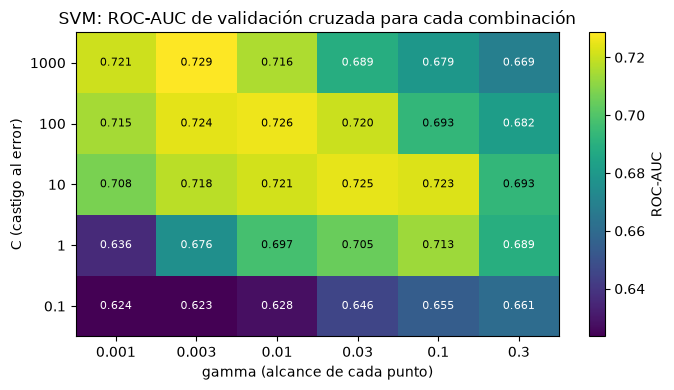

In [4]:
res_svm = pd.DataFrame(busquedas["SVM"].cv_results_)
mapa = res_svm.pivot_table(index="param_modelo__C", columns="param_modelo__gamma", values="mean_test_score")
mapa.to_csv(MODELO_DIR / "grilla_svm.csv")
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(mapa.values, cmap="viridis", aspect="auto", origin="lower")
ax.set_xticks(range(mapa.shape[1]), [f"{g:g}" for g in mapa.columns])
ax.set_yticks(range(mapa.shape[0]), [f"{c:g}" for c in mapa.index])
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8, color="white" if v < mapa.values.mean() else "black")
ax.set_xlabel("gamma (alcance de cada punto)")
ax.set_ylabel("C (castigo al error)")
ax.set_title("SVM: ROC-AUC de validación cruzada para cada combinación")
fig.colorbar(im, ax=ax, label="ROC-AUC")
plt.tight_layout()
guardar_figura(fig, "nb20_2.png")
plt.show()

## Paso 3: los modelos ajustados (y el Stacking armado con los mejores SVM, Random Forest y Gradient Boosting)
Se vuelve a medir cada modelo con sus hiperparámetros elegidos, con la misma validación cruzada. El Stacking no tiene
búsqueda propia: combina las versiones ajustadas de sus tres modelos base, y su regresión logística final aprende cuánto
confiar en cada uno usando predicciones *fuera de pliegue* (nunca las del mismo dato con el que se entrenó).

In [5]:
filas = []
for nombre in MODELOS:
    t0 = time.time()
    res = evaluar_cv(modelo(nombre, COMPLETA, hp))
    filas.append({"modelo": nombre, "familia": FAMILIAS[nombre][0], "configuracion": "ajustado", **res,
                  "segundos": time.time() - t0})
ajustado = pd.DataFrame(filas)
metricas_cv = pd.concat([defecto, ajustado], ignore_index=True)
metricas_cv.to_csv(MODELO_DIR / "metricas_cv.csv", index=False)
comparacion = (metricas_cv.pivot_table(index="modelo", columns="configuracion", values="roc_auc")
               .reindex(MODELOS)[["por defecto", "ajustado"]])
comparacion["mejora"] = comparacion["ajustado"] - comparacion["por defecto"]
display(comparacion.round(3))
display(ajustado.set_index("modelo")[["roc_auc", "roc_auc_desvio", "exactitud", "f1"]].round(3))

configuracion,por defecto,ajustado,mejora
modelo,,,
Línea base (clase mayoritaria),0.500,0.500,0.000
Regresión logística,0.729,0.730,0.001
SVM,0.706,0.729,0.023
Bagging,0.716,0.753,0.038
Random Forest,0.734,0.753,0.020
AdaBoost,0.712,0.728,0.016
Gradient Boosting,0.724,0.744,0.021
Stacking,0.736,0.753,0.017


,roc_auc,roc_auc_desvio,exactitud,f1
modelo,,,,
Línea base (clase mayoritaria),0.500,0.000,0.510,0.000
Regresión logística,0.730,0.051,0.674,0.674
SVM,0.729,0.037,0.670,0.658
Bagging,0.753,0.034,0.667,0.671
Random Forest,0.753,0.031,0.673,0.676
AdaBoost,0.728,0.044,0.665,0.684
Gradient Boosting,0.744,0.039,0.667,0.671
Stacking,0.753,0.035,0.671,0.671


In [6]:
hp_tabla = pd.DataFrame([{"modelo": m, "hiperparametro": k, "valor": v} for m, p in hp.items() for k, v in p.items()])
hp_tabla.to_csv(MODELO_DIR / "hiperparametros.csv", index=False)
mejor = ajustado.loc[ajustado["roc_auc"].idxmax(), "modelo"]
print("mejor modelo en validación cruzada:", mejor, round(ajustado["roc_auc"].max(), 3))
# Controles: el ajuste se hizo con validación cruzada y todos los modelos reales superan a la línea base.
assert (ajustado.loc[~ajustado["modelo"].str.startswith("Línea"), "roc_auc"] > 0.55).all()
assert set(hp) == set(MODELOS) - {"Línea base (clase mayoritaria)", "Stacking"}

mejor modelo en validación cruzada: Bagging 0.753


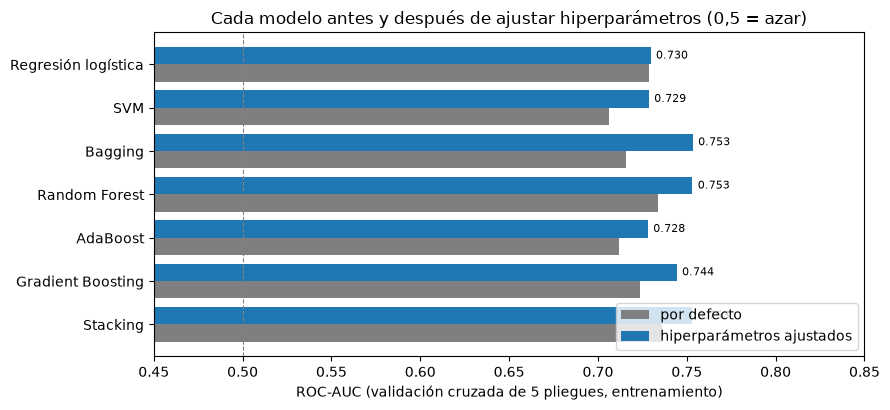

In [7]:
orden = [m for m in MODELOS if not m.startswith("Línea")]
fig, ax = plt.subplots(figsize=(9, 4.2))
pos = np.arange(len(orden))
ax.barh(pos + 0.2, comparacion.loc[orden, "por defecto"], 0.4, color="tab:gray", label="por defecto")
ax.barh(pos - 0.2, comparacion.loc[orden, "ajustado"], 0.4, color="tab:blue", label="hiperparámetros ajustados")
for i, m in enumerate(orden):
    ax.text(comparacion.loc[m, "ajustado"] + 0.003, i - 0.2, f"{comparacion.loc[m, 'ajustado']:.3f}", va="center", fontsize=8)
ax.axvline(0.5, color="gray", ls="--", lw=0.8)
ax.set_yticks(pos, orden)
ax.invert_yaxis()
ax.set_xlim(0.45, max(0.85, comparacion["ajustado"].max() + 0.04))
ax.set_xlabel("ROC-AUC (validación cruzada de 5 pliegues, entrenamiento)")
ax.set_title("Cada modelo antes y después de ajustar hiperparámetros (0,5 = azar)")
ax.legend(loc="lower right")
plt.tight_layout()
guardar_figura(fig, "nb20_1.png")
plt.show()

## Lectura
- **Todos los modelos superan con claridad a la línea base** (0,500): el mejor llega a un ROC-AUC de validación cruzada de
  **0,753**. Es decir, tomando al azar un proceso que acumula mora y uno que no, el modelo ordena bien al par 3 de cada 4 veces.
- **Tres modelos empatan arriba:** Bagging (0,7534), Random Forest (0,7532) y Stacking (0,7530). La diferencia entre ellos
  (0,0004) es cien veces menor que el desvío entre pliegues (≈ 0,03): con estos datos **no se puede decir que uno sea mejor**.
  Por el redondeo de la tercera cifra, el notebook 21 toma a **Bagging** como «mejor modelo».
- **Siguen** Gradient Boosting (0,744), regresión logística (0,730), SVM (0,729) y AdaBoost (0,728). Que la logística, un
  modelo lineal simple, quede a 0,02 de los ensambles indica que la señal es **moderada y casi aditiva**: no hay interacciones
  complejas que solo un ensamble pueda capturar.
- **Ajustar hiperparámetros mejora a todos** entre +0,016 (AdaBoost) y +0,038 (Bagging); a la logística casi nada (+0,001,
  solo tiene una perilla). Lo que más ayudó a los árboles fue **no dejarlos memorizar**: hojas con al menos 3 o 4 procesos y
  cada árbol mirando solo una parte de las filas y de las variables.
- **SVM:** la grilla va de 0,623 a 0,729. El mejor par es `C = 1000` con `gamma = 0,003`: una frontera muy suave (gamma bajo)
  que castiga fuerte los errores. Con gamma alto (frontera muy curva) el AUC cae: el SVM sobreajusta.
- **Stacking no supera a su mejor componente.** Combinar SVM, Random Forest y Gradient Boosting da 0,753, lo mismo que el
  Random Forest solo. Lo más probable es que los tres modelos base aprendan la misma señal y fallen en procesos parecidos;
  cuando eso pasa, combinarlos no agrega información.
